# Modelos de Clasificación

En este notebook se construyen, evalúan y comparan los modelos de clasificación utilizados para estimar la probabilidad de que una persona tenga diabetes o prediabetes a partir de los indicadores de salud de la encuesta BRFSS 2015. Es la continuación del análisis univariado y bivariado: aquí se usan las mismas variables, ya exploradas, como insumo de los modelos que alimentan el tablero **GlucoRisk**.

## 1. Introducción

El análisis exploratorio mostró que variables como la salud general percibida, el índice de masa corporal, la edad, la presión arterial alta y el colesterol alto se asocian de forma significativa con la diabetes. Sin embargo, una asociación individual no dice qué tan bien se puede **predecir** la condición de una persona cuando se consideran todas las variables al mismo tiempo.

Para responder esa pregunta se entrenan seis algoritmos de aprendizaje supervisado con supuestos distintos: Regresión Logística, Árbol de Decisión, Random Forest, XGBoost, K vecinos más cercanos (KNN) y Naive Bayes. Todos se evalúan con los mismos datos y las mismas métricas, de modo que la comparación sea justa. El objetivo práctico es contar con un modelo de **tamizaje**: una herramienta que, a partir de preguntas de una encuesta y sin exámenes de laboratorio, ayude a priorizar a qué personas conviene hacerles una prueba de glucosa.

## 2. Objetivos

**Objetivo general**

Construir y comparar modelos de clasificación que estimen la probabilidad de diabetes o prediabetes a partir de las 21 variables del conjunto de datos `diabetes_binary_5050split_health_indicators_BRFSS2015`, y seleccionar el de mejor desempeño.

**Objetivos específicos**

- Entrenar seis clasificadores con una partición estratificada de entrenamiento y prueba.
- Evaluar cada modelo con exactitud, precisión, sensibilidad (recall), F1 y ROC-AUC, y estimar su estabilidad mediante validación cruzada.
- Analizar el sobreajuste comparando el desempeño en entrenamiento, validación cruzada y prueba.
- Estudiar el efecto del umbral de decisión y la calibración de las probabilidades, incluido el ajuste a la prevalencia real de la población.
- Identificar qué variables pesan más en las predicciones mediante importancia por permutación y odds ratios.

## 3. Marco Teórico

**Clasificación supervisada**: tarea de aprendizaje automático en la que, a partir de un conjunto de ejemplos con la respuesta conocida, se aprende una función que asigna una clase a nuevas observaciones. En este caso la respuesta es binaria (`Diabetes` = 1 con diabetes o prediabetes, `Diabetes` = 0 sin ella) y el modelo estima $P(y = 1 \mid x)$, la probabilidad de pertenecer a la clase positiva dado el vector de variables $x$.

**Regresión Logística**: modelo lineal generalizado que relaciona las variables con el logaritmo de los odds de la clase positiva:

$$\log\frac{p}{1-p} = \beta_0 + \beta_1 x_1 + \dots + \beta_k x_k$$

Su principal ventaja es la interpretabilidad: $e^{\beta_j}$ es el *odds ratio* asociado a un aumento de una unidad en $x_j$. Cuando las variables están estandarizadas, el odds ratio corresponde a un aumento de una desviación estándar y los coeficientes son comparables entre sí.

**Árbol de Decisión**: divide el espacio de las variables mediante reglas sucesivas del tipo *si IMC > 30 entonces…*, eligiendo en cada nodo la división que más reduce la impureza (índice de Gini). Es fácil de leer, pero es inestable y tiende a sobreajustarse si no se limita su profundidad.

**Random Forest**: ensamble de muchos árboles, cada uno entrenado sobre una muestra *bootstrap* de los datos y considerando un subconjunto aleatorio de variables en cada división. La predicción final es el promedio de los árboles, lo que reduce la varianza respecto a un árbol individual (Breiman, 2001).

**XGBoost**: implementación de *gradient boosting* en la que los árboles se construyen de forma secuencial y cada uno corrige los errores de los anteriores, siguiendo el gradiente de la función de pérdida. Incluye regularización y submuestreo para controlar el sobreajuste (Chen y Guestrin, 2016).

**K vecinos más cercanos (KNN)**: clasifica una observación según la proporción de casos positivos entre sus $k$ vecinos más cercanos en el espacio de las variables. No aprende parámetros, pero depende de la escala, por lo que las variables deben estandarizarse.

**Naive Bayes gaussiano**: aplica el teorema de Bayes suponiendo que las variables son independientes dentro de cada clase y que siguen una distribución normal. Ese supuesto rara vez se cumple, pero el modelo es rápido y sirve como línea base.

**Métricas de evaluación**: a partir de la matriz de confusión (verdaderos positivos VP, falsos positivos FP, verdaderos negativos VN y falsos negativos FN) se calculan:

- **Exactitud (accuracy)** $= \frac{VP + VN}{n}$: proporción de aciertos. Es interpretable porque las clases están balanceadas.
- **Precisión** $= \frac{VP}{VP + FP}$: de las personas que el modelo marca como positivas, cuántas lo son realmente.
- **Sensibilidad o recall** $= \frac{VP}{VP + FN}$: de las personas con diabetes, cuántas detecta el modelo.
- **F1**: media armónica de precisión y recall.
- **ROC-AUC**: área bajo la curva que relaciona la tasa de verdaderos positivos con la de falsos positivos para todos los umbrales posibles. Equivale a la probabilidad de que un caso positivo elegido al azar reciba una probabilidad mayor que un caso negativo elegido al azar (Fawcett, 2006). No depende del umbral.

En tamizaje se priorizan el **ROC-AUC** y el **recall**, porque dejar sin detectar a una persona con diabetes es más costoso que pedirle una prueba adicional a un falso positivo.

**Validación cruzada**: técnica que divide los datos de entrenamiento en $k$ partes; el modelo se entrena $k$ veces dejando cada vez una parte fuera para evaluarlo. La media de las $k$ evaluaciones estima el desempeño esperado y su desviación estándar indica qué tan estable es el modelo.

**Sobreajuste**: ocurre cuando un modelo aprende detalles particulares de los datos de entrenamiento que no se repiten en datos nuevos. Se detecta cuando el desempeño en entrenamiento es claramente mayor que en validación o prueba.

**Balance de clases y ajuste a la prevalencia**: el conjunto de datos está balanceado (50% con diabetes y 50% sin ella), lo que permite que el modelo aprenda ambas clases por igual. La consecuencia es que sus probabilidades corresponden a una población donde la mitad tiene la condición. Si la prevalencia real es $\pi$ (≈ 13.9% en el BRFSS 2015 completo), la probabilidad se corrige multiplicando los odds por el cociente de odds a priori (Saerens et al., 2002):

$$\frac{p'}{1-p'} = \frac{p}{1-p}\cdot\frac{\pi/(1-\pi)}{0.5/0.5}$$

Esta corrección cambia el valor de la probabilidad pero no el orden de las personas, por lo que el ROC-AUC no se modifica.

**Importancia por permutación**: mide cuánto empeora una métrica (aquí el ROC-AUC) cuando se desordenan al azar los valores de una variable, rompiendo su relación con la respuesta. Una caída grande indica que el modelo depende mucho de esa variable. Funciona con cualquier modelo.

## 4. Metodología

El trabajo de modelado siguió estos pasos:

1. **Preparación de datos**: se renombran las variables igual que en el análisis exploratorio y se eliminan los registros duplicados.
2. **Partición**: 80% de los datos para entrenamiento y 20% para prueba, de forma estratificada por la variable `Diabetes` y con semilla fija (`42`) para que los resultados sean reproducibles. El conjunto de prueba no se usa en ningún momento del entrenamiento.
3. **Escalado**: la Regresión Logística y KNN se entrenan dentro de un `Pipeline` con `StandardScaler`, de modo que la media y la desviación estándar se calculan solo con los datos de entrenamiento. Los modelos basados en árboles y Naive Bayes no requieren escalado.
4. **Entrenamiento**: se ajustan los seis modelos con los hiperparámetros indicados en la sección 7.
5. **Evaluación**: se calculan las métricas en el conjunto de prueba con umbral 0.5, se estima el ROC-AUC con validación cruzada estratificada de 5 particiones y se comparan las curvas ROC y las matrices de confusión.
6. **Diagnóstico**: análisis de sobreajuste, del umbral de decisión y de la calibración de las probabilidades.
7. **Interpretación**: importancia por permutación del mejor modelo, odds ratios de la Regresión Logística y visualización de las primeras reglas del Árbol de Decisión.
8. **Selección**: el modelo final es el de mayor ROC-AUC en el conjunto de prueba, considerando también su estabilidad y su nivel de sobreajuste.

## Librerías

In [1]:
import time
from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, roc_curve, confusion_matrix,
                             precision_recall_curve)
from sklearn.calibration import calibration_curve
from sklearn.inspection import permutation_importance
from xgboost import XGBClassifier

import warnings
warnings.filterwarnings('ignore')

sns.set_theme(style='whitegrid')

SEED = 42
paleta = {0.0: '#4C72B0', 1.0: '#DD8452'}
etiquetas_diabetes = {0.0: 'Sin diabetes', 1.0: 'Con diabetes / prediabetes'}
COLORES_MODELOS = {
    'XGBoost': '#C44E52',
    'Random Forest': '#4C72B0',
    'Regresión Logística': '#DD8452',
    'Árbol de Decisión': '#55A868',
    'KNN': '#8172B3',
    'Naive Bayes': '#937860',
}

## 5. Carga y preparación de datos

In [2]:
# Ruta válida tanto si el notebook se ejecuta desde la raíz del repositorio
# como desde la carpeta notebooks/
nombre = 'diabetes_binary_5050split_health_indicators_BRFSS2015.csv'
candidatas = [Path('data') / nombre, Path('Data') / nombre, Path('..') / 'data' / nombre]
filename = next(p for p in candidatas if p.exists())

df = pd.read_csv(filename, sep=',')

df = df.rename(columns={
    'Diabetes_binary': 'Diabetes',
    'HighBP':         'PA_alta',
    'HighChol':     'col_alto',
    'CholCheck':   'CheckCol',
    'BMI':  'IMC',
    'Smoker':   'Fumador',
    'Stroke':      'derrame',
    'HeartDiseaseorAttack': 'EnfCardi',
    'PhysActivity':  'ActFisi',
    'Fruits':    'fruta',
    'Veggies':   'vegetales',
    'HvyAlcoholConsump':     'Alcohlico',
    'AnyHealthcare':        'eps',
    'NoDocbcCost':    'AfordabilidadMedica',
    'GenHlth':         'SaludG',
    'MentHlth':        'SaludM',
    'PhysHlth':        'SaludF',
    'DiffWalk':        'DificultadCaminar',
    'Sex': 'Genero',
    'Age': 'Edad',
    'Education': 'Educacion',
    'Income': 'Ingresos'
})[[
    'Diabetes', 'PA_alta', 'col_alto', 'CheckCol',
    'IMC', 'Fumador', 'derrame', 'EnfCardi', 'ActFisi',
    'fruta', 'vegetales', 'Alcohlico', 'eps', 'AfordabilidadMedica',
    'SaludG', 'SaludM', 'SaludF', 'DificultadCaminar', 'Genero',
    'Edad', 'Educacion', 'Ingresos'
]]

n_original = len(df)
df = df.drop_duplicates().reset_index(drop=True)

print(f"Registros originales:          {n_original:,}")
print(f"Registros duplicados quitados: {n_original - len(df):,}")
print(f"Registros únicos:              {len(df):,}")
df.head()

Registros originales:          70,692
Registros duplicados quitados: 1,635
Registros únicos:              69,057


,Diabetes,PA_alta,col_alto,CheckCol,IMC,Fumador,derrame,EnfCardi,ActFisi,fruta,...,eps,AfordabilidadMedica,SaludG,SaludM,SaludF,DificultadCaminar,Genero,Edad,Educacion,Ingresos
0,0.0,1.0,0.0,1.0,26.0,0.0,0.0,0.0,1.0,0.0,...,1.0,0.0,3.0,5.0,30.0,0.0,1.0,4.0,6.0,8.0
1,0.0,1.0,1.0,1.0,26.0,1.0,1.0,0.0,0.0,1.0,...,1.0,0.0,3.0,0.0,0.0,0.0,1.0,12.0,6.0,8.0
2,0.0,0.0,0.0,1.0,26.0,0.0,0.0,0.0,1.0,1.0,...,1.0,0.0,1.0,0.0,10.0,0.0,1.0,13.0,6.0,8.0
3,0.0,1.0,1.0,1.0,28.0,1.0,0.0,0.0,1.0,1.0,...,1.0,0.0,3.0,0.0,3.0,0.0,1.0,11.0,6.0,8.0
4,0.0,0.0,0.0,1.0,29.0,1.0,0.0,0.0,1.0,1.0,...,1.0,0.0,2.0,0.0,0.0,0.0,0.0,8.0,5.0,8.0


In [3]:
target = 'Diabetes'
variables = [c for c in df.columns if c != target]

X = df[variables]
y = df[target].astype(int)

print(f"Variables predictoras: {len(variables)}")
print(f"Valores nulos: {df.isna().sum().sum()}")
(y.value_counts().rename(index={0: 'Sin diabetes', 1: 'Con diabetes / prediabetes'})
  .to_frame('Frecuencia')
  .assign(Porcentaje=lambda t: (t['Frecuencia'] / t['Frecuencia'].sum() * 100).round(1)))

Variables predictoras: 21
Valores nulos: 0


,Frecuencia,Porcentaje
Diabetes,,
Con diabetes / prediabetes,35097,50.8
Sin diabetes,33960,49.2


El conjunto original tiene 70 692 registros, de los cuales 1 635 son duplicados exactos. Al eliminarlos quedan **69 057 registros únicos** y 21 variables predictoras, sin valores nulos. La base original está perfectamente balanceada (35 346 personas con diabetes y 35 346 sin ella); después de quitar duplicados la proporción queda en 50.8% con diabetes o prediabetes y 49.2% sin ella, es decir, sigue prácticamente balanceada. Por eso no fue necesario aplicar técnicas de remuestreo ni pesos por clase, y la exactitud es una métrica interpretable.

## 6. Partición en entrenamiento y prueba

Se reserva el 20% de los datos como conjunto de prueba. La partición es **estratificada**, lo que garantiza que la proporción de personas con y sin diabetes sea la misma en ambos conjuntos.

In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=SEED)

particion = pd.DataFrame({
    'Registros': [len(X_train), len(X_test)],
    '% con diabetes': [y_train.mean() * 100, y_test.mean() * 100],
}, index=['Entrenamiento', 'Prueba']).round(2)
particion

,Registros,% con diabetes
Entrenamiento,55245,50.82
Prueba,13812,50.83


El conjunto de entrenamiento quedó con 55 245 registros y el de prueba con 13 812. Gracias a la estratificación, el porcentaje de personas con diabetes es prácticamente idéntico en ambos (50.82% y 50.83%), de modo que el conjunto de prueba representa fielmente a los datos de entrenamiento.

## 7. Definición de los modelos

A continuación se definen los seis modelos con sus hiperparámetros. Los valores se eligieron para limitar el sobreajuste de los modelos más flexibles (profundidad máxima y número mínimo de observaciones por hoja en los árboles) y se mantuvieron fijos para todos los análisis.

| Modelo | Hiperparámetros | Escalado |
|---|---|---|
| XGBoost | 400 árboles, tasa de aprendizaje 0.05, profundidad máx. 5, `subsample` 0.8, `colsample_bytree` 0.8, `min_child_weight` 5 | No |
| Random Forest | 200 árboles, profundidad máx. 14, mínimo 10 observaciones por hoja | No |
| Regresión Logística | Regularización L2 por defecto (C = 1), máx. 2000 iteraciones | Sí |
| Árbol de Decisión | Profundidad máx. 8, mínimo 50 observaciones por hoja | No |
| KNN | k = 35 vecinos, distancia euclidiana | Sí |
| Naive Bayes | Gaussiano, sin hiperparámetros | No |

In [5]:
modelos = {
    'XGBoost': XGBClassifier(
        n_estimators=400, learning_rate=0.05, max_depth=5, subsample=0.8,
        colsample_bytree=0.8, min_child_weight=5, eval_metric='logloss',
        random_state=SEED, n_jobs=-1),
    'Random Forest': RandomForestClassifier(
        n_estimators=200, max_depth=14, min_samples_leaf=10,
        random_state=SEED, n_jobs=-1),
    'Regresión Logística': Pipeline([
        ('scaler', StandardScaler()),
        ('clf', LogisticRegression(max_iter=2000))]),
    'Árbol de Decisión': DecisionTreeClassifier(
        max_depth=8, min_samples_leaf=50, random_state=SEED),
    'KNN': Pipeline([
        ('scaler', StandardScaler()),
        ('clf', KNeighborsClassifier(n_neighbors=35))]),
    'Naive Bayes': GaussianNB(),
}

## 8. Entrenamiento y evaluación en el conjunto de prueba

Cada modelo se entrena con el conjunto de entrenamiento y se evalúa sobre el conjunto de prueba. Las métricas de clasificación se calculan con un umbral de 0.5 sobre la probabilidad estimada. Además, se estima el ROC-AUC con validación cruzada estratificada de 5 particiones sobre el conjunto de entrenamiento.

In [6]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

resultados, prob_test, prob_train, auc_folds, tiempos = [], {}, {}, {}, {}

for nombre, modelo in modelos.items():
    t0 = time.time()
    modelo.fit(X_train, y_train)
    tiempos[nombre] = time.time() - t0

    p_te = modelo.predict_proba(X_test)[:, 1]
    p_tr = modelo.predict_proba(X_train)[:, 1]
    y_pred = (p_te >= 0.5).astype(int)
    prob_test[nombre], prob_train[nombre] = p_te, p_tr

    auc_folds[nombre] = cross_val_score(modelo, X_train, y_train, cv=cv,
                                        scoring='roc_auc', n_jobs=1)

    resultados.append({
        'Modelo': nombre,
        'ROC-AUC': roc_auc_score(y_test, p_te),
        'Exactitud': accuracy_score(y_test, y_pred),
        'Precisión': precision_score(y_test, y_pred),
        'Recall': recall_score(y_test, y_pred),
        'F1': f1_score(y_test, y_pred),
        'AUC CV (media)': auc_folds[nombre].mean(),
        'AUC CV (ds)': auc_folds[nombre].std(),
        'AUC entrenamiento': roc_auc_score(y_train, p_tr),
        'Tiempo de ajuste (s)': tiempos[nombre],
    })
    print(f"{nombre:<22} listo en {time.time() - t0:5.1f} s")

tabla_resultados = (pd.DataFrame(resultados)
                    .sort_values('ROC-AUC', ascending=False)
                    .reset_index(drop=True))
mejor = tabla_resultados.loc[0, 'Modelo']

XGBoost                listo en   7.2 s


Random Forest          listo en  18.9 s


Regresión Logística    listo en   0.5 s


Árbol de Decisión      listo en   0.7 s


KNN                    listo en  13.2 s


Naive Bayes            listo en   0.3 s


In [7]:
(tabla_resultados[['Modelo', 'ROC-AUC', 'Exactitud', 'Precisión', 'Recall', 'F1']]
 .style.format(precision=4)
 .highlight_max(subset=['ROC-AUC', 'Exactitud', 'Precisión', 'Recall', 'F1'], color='#fde2c8')
 .hide(axis='index'))

Modelo,ROC-AUC,Exactitud,Precisión,Recall,F1
XGBoost,0.8235,0.7493,0.7315,0.8004,0.7644
Random Forest,0.8209,0.7444,0.7271,0.7956,0.7598
Regresión Logística,0.8174,0.7450,0.7380,0.7726,0.7549
Árbol de Decisión,0.8105,0.7331,0.7143,0.7912,0.7508
KNN,0.8053,0.7360,0.7186,0.7900,0.7526
Naive Bayes,0.7800,0.7186,0.7254,0.7181,0.7217


**XGBoost** obtiene el mejor desempeño en casi todas las métricas: ROC-AUC de 0.8235, exactitud de 74.9%, recall de 80.0% y F1 de 0.764. Le siguen muy de cerca Random Forest (AUC 0.8209) y la Regresión Logística (AUC 0.8174), que además tiene la precisión más alta (73.8%). Naive Bayes es el modelo más débil (AUC 0.780), lo que es esperable porque su supuesto de independencia entre variables no se cumple: varias de ellas están relacionadas entre sí, como la salud general, la salud física y la dificultad para caminar.

La diferencia de AUC entre el primer y el tercer modelo es de apenas 0.006, lo que indica que el límite del desempeño lo pone la información disponible en la encuesta más que el algoritmo elegido.

**Gráfico comparativo de métricas**

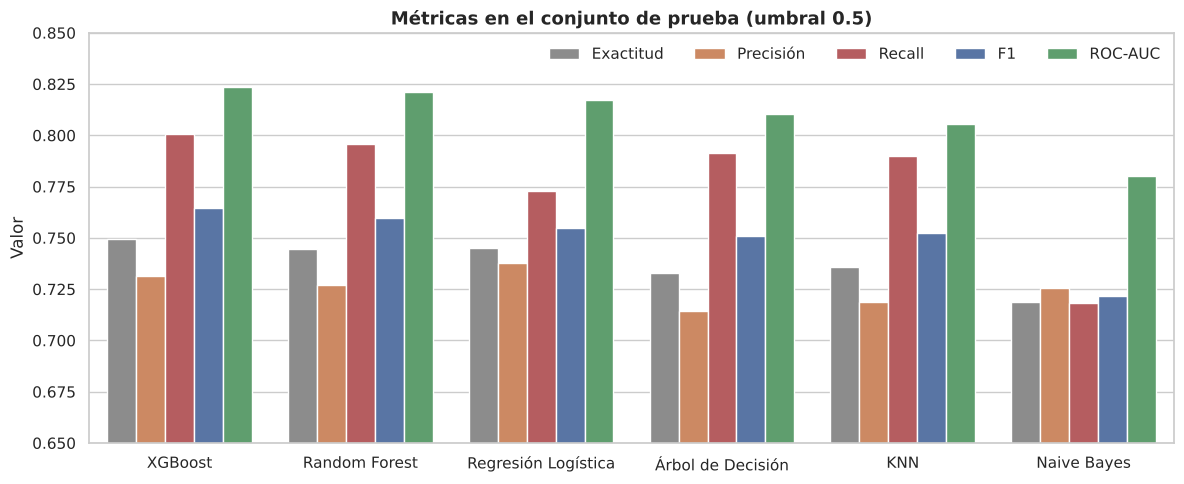

In [8]:
metricas = ['Exactitud', 'Precisión', 'Recall', 'F1', 'ROC-AUC']
largo = tabla_resultados.melt(id_vars='Modelo', value_vars=metricas,
                              var_name='Métrica', value_name='Valor')

fig, ax = plt.subplots(figsize=(12, 5))
sns.barplot(data=largo, x='Modelo', y='Valor', hue='Métrica', ax=ax,
            palette=['#8C8C8C', '#DD8452', '#C44E52', '#4C72B0', '#55A868'])
ax.set_ylim(0.65, 0.85)
ax.set_title('Métricas en el conjunto de prueba (umbral 0.5)', fontsize=13, fontweight='bold')
ax.set_xlabel('')
ax.set_ylabel('Valor')
ax.legend(title='', ncol=5, loc='upper right', frameon=False)
plt.tight_layout()
plt.show()

En el gráfico se aprecia que en los cinco primeros modelos el recall (rojo) es claramente mayor que la precisión (naranja): con umbral 0.5 los modelos tienden a marcar como positivas a más personas de las que realmente tienen diabetes. Para un modelo de tamizaje esto es deseable, porque prioriza no dejar casos sin detectar. Naive Bayes es la excepción: sus cinco métricas están en un nivel similar y más bajo.

## 9. Validación cruzada

La validación cruzada permite verificar que el resultado de la partición de prueba no se deba al azar. Para cada modelo se muestran los cinco valores de ROC-AUC obtenidos en las particiones de validación.

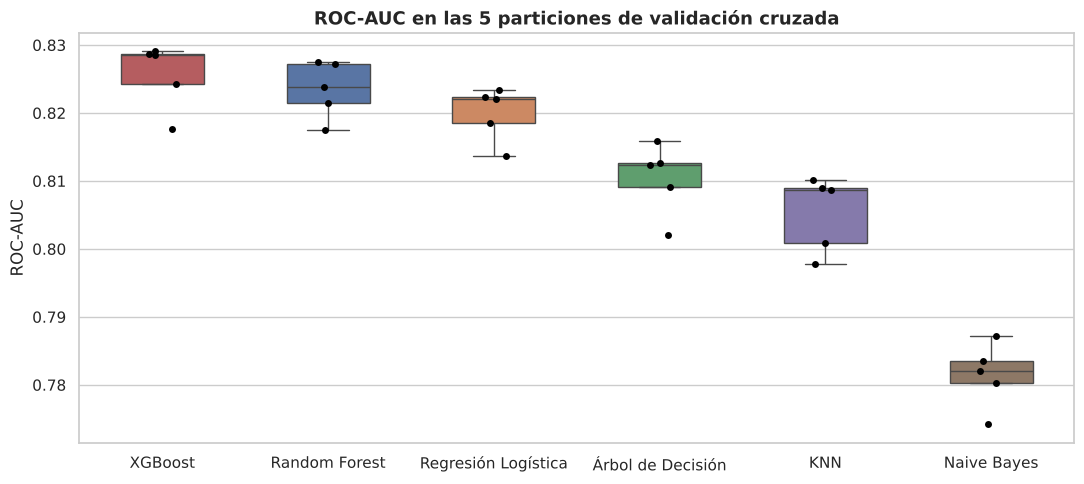

,Modelo,AUC CV (media),AUC CV (ds),ROC-AUC
0,XGBoost,0.8256,0.0044,0.8235
1,Random Forest,0.8235,0.0037,0.8209
2,Regresión Logística,0.8200,0.0036,0.8174
3,Árbol de Decisión,0.8104,0.0047,0.8105
4,KNN,0.8053,0.0050,0.8053
5,Naive Bayes,0.7814,0.0043,0.7800


In [9]:
folds = (pd.DataFrame(auc_folds)
         .melt(var_name='Modelo', value_name='ROC-AUC'))
orden = tabla_resultados['Modelo'].tolist()

fig, ax = plt.subplots(figsize=(11, 5))
sns.boxplot(data=folds, x='Modelo', y='ROC-AUC', order=orden, ax=ax,
            palette=COLORES_MODELOS, width=0.5, fliersize=0)
sns.stripplot(data=folds, x='Modelo', y='ROC-AUC', order=orden, ax=ax,
              color='black', size=5, jitter=0.08)
ax.set_title('ROC-AUC en las 5 particiones de validación cruzada', fontsize=13, fontweight='bold')
ax.set_xlabel('')
plt.tight_layout()
plt.show()

tabla_resultados[['Modelo', 'AUC CV (media)', 'AUC CV (ds)', 'ROC-AUC']].round(4)

Los resultados de la validación cruzada son muy estables: la desviación estándar del ROC-AUC entre particiones está entre 0.0036 y 0.0050 para todos los modelos. Además, el AUC medio de validación cruzada es casi igual al AUC en el conjunto de prueba (por ejemplo, 0.8256 frente a 0.8235 en XGBoost), lo que confirma que el resultado de la partición de prueba no se debe al azar. El orden de los modelos se mantiene igual en ambas evaluaciones, aunque las cajas de XGBoost, Random Forest y Regresión Logística se solapan parcialmente, lo que refuerza que su diferencia es pequeña.

## 10. Curvas ROC

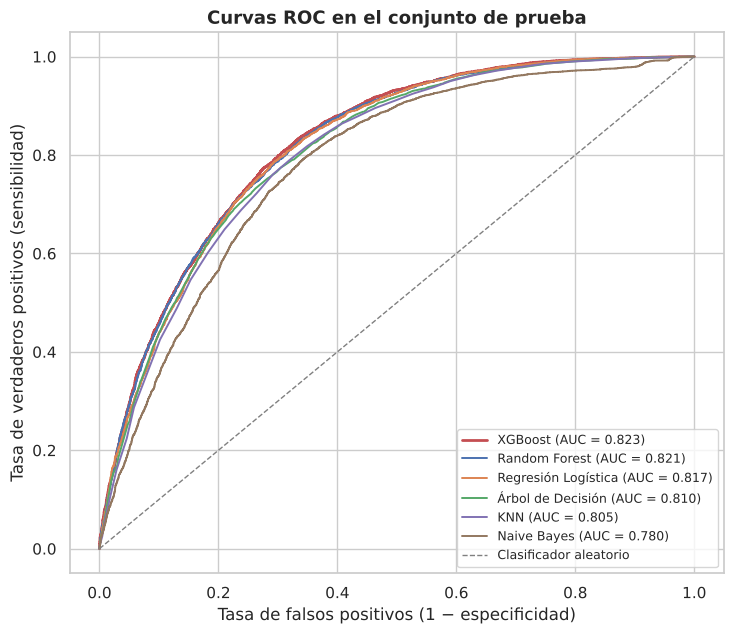

In [10]:
fig, ax = plt.subplots(figsize=(7.5, 6.5))
for nombre in orden:
    fpr, tpr, _ = roc_curve(y_test, prob_test[nombre])
    auc = roc_auc_score(y_test, prob_test[nombre])
    ax.plot(fpr, tpr, color=COLORES_MODELOS[nombre], lw=2 if nombre == mejor else 1.4,
            label=f'{nombre} (AUC = {auc:.3f})')
ax.plot([0, 1], [0, 1], ls='--', color='grey', lw=1, label='Clasificador aleatorio')
ax.set_xlabel('Tasa de falsos positivos (1 − especificidad)')
ax.set_ylabel('Tasa de verdaderos positivos (sensibilidad)')
ax.set_title('Curvas ROC en el conjunto de prueba', fontsize=13, fontweight='bold')
ax.legend(loc='lower right', fontsize=9)
plt.tight_layout()
plt.show()

Las curvas ROC de XGBoost, Random Forest y Regresión Logística prácticamente se superponen, y las del Árbol de Decisión y KNN quedan apenas por debajo. Todas están muy por encima de la diagonal del clasificador aleatorio (AUC = 0.5). Naive Bayes es la única curva que se separa visiblemente, sobre todo en la zona de tasas de falsos positivos entre 0.1 y 0.5. Un AUC de 0.82 significa que, si se elige al azar una persona con diabetes y otra sin ella, el mejor modelo le asigna mayor probabilidad a la persona con diabetes en el 82% de los casos.

## 11. Matrices de confusión

Cada matriz muestra, para el conjunto de prueba y con umbral 0.5, el número de personas y el porcentaje sobre el total de su clase real (por fila).

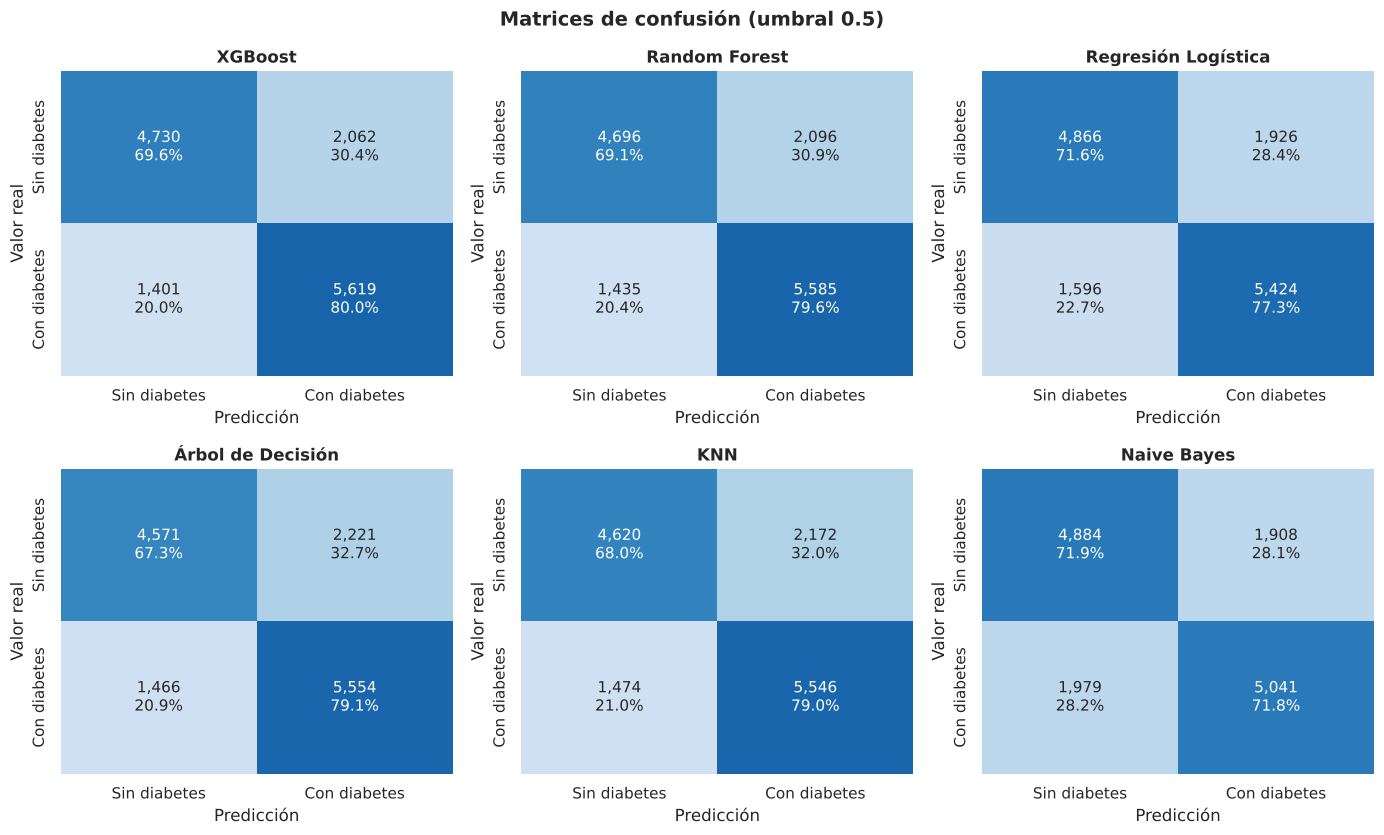

In [11]:
fig, axes = plt.subplots(2, 3, figsize=(14, 8.5))
for ax, nombre in zip(axes.ravel(), orden):
    y_pred = (prob_test[nombre] >= 0.5).astype(int)
    cm = confusion_matrix(y_test, y_pred)
    cm_pct = cm / cm.sum(axis=1, keepdims=True) * 100
    anot = np.array([[f'{cm[i, j]:,}\n{cm_pct[i, j]:.1f}%' for j in range(2)] for i in range(2)])
    sns.heatmap(cm_pct, annot=anot, fmt='', cmap='Blues', vmin=0, vmax=100, cbar=False,
                ax=ax, annot_kws={'fontsize': 11},
                xticklabels=['Sin diabetes', 'Con diabetes'],
                yticklabels=['Sin diabetes', 'Con diabetes'])
    ax.set_title(nombre, fontsize=12, fontweight='bold')
    ax.set_xlabel('Predicción')
    ax.set_ylabel('Valor real')
plt.suptitle('Matrices de confusión (umbral 0.5)', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

En XGBoost, de las 7 020 personas con diabetes del conjunto de prueba el modelo detecta correctamente 5 619 (80.0%) y deja sin detectar 1 401 (20.0%). De las 6 792 personas sin diabetes, clasifica correctamente 4 730 (69.6%) y genera 2 062 falsas alarmas (30.4%). El patrón se repite en los demás modelos: todos aciertan más en la clase con diabetes que en la clase sin diabetes. Naive Bayes es el que menos casos positivos detecta (71.8%), mientras que la Regresión Logística es la más equilibrada entre ambas clases (77.3% y 71.6%).

## 12. Análisis de sobreajuste

Se compara el ROC-AUC obtenido sobre los mismos datos de entrenamiento con el de validación cruzada y el de prueba. Una brecha grande entre entrenamiento y prueba indica que el modelo memorizó patrones que no generalizan.

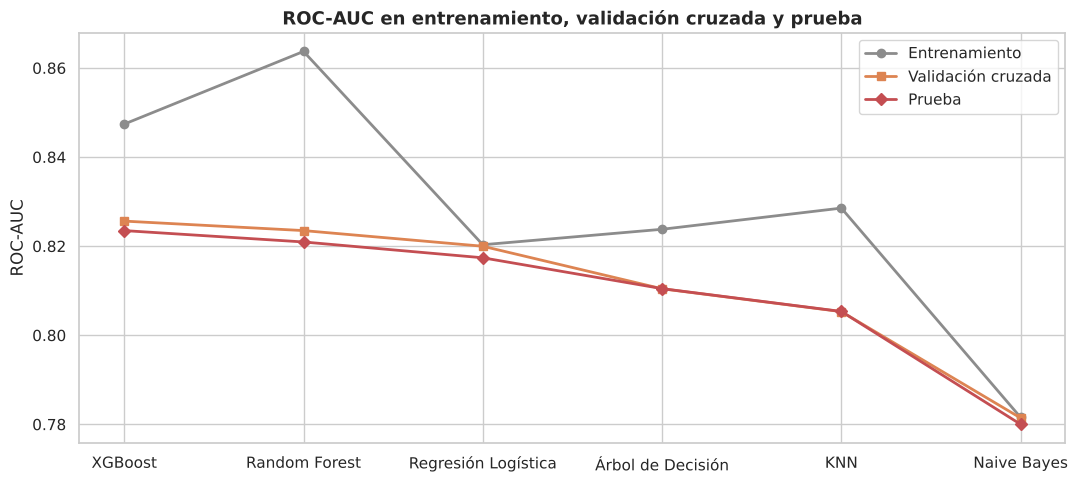

,Modelo,AUC entrenamiento,AUC CV (media),ROC-AUC,Brecha entrenamiento − prueba
0,XGBoost,0.8474,0.8256,0.8235,0.0239
1,Random Forest,0.8637,0.8235,0.8209,0.0428
2,Regresión Logística,0.8203,0.8200,0.8174,0.0029
3,Árbol de Decisión,0.8238,0.8104,0.8105,0.0133
4,KNN,0.8285,0.8053,0.8053,0.0232
5,Naive Bayes,0.7815,0.7814,0.7800,0.0015


In [12]:
sobreajuste = tabla_resultados[['Modelo', 'AUC entrenamiento', 'AUC CV (media)', 'ROC-AUC']].copy()
sobreajuste['Brecha entrenamiento − prueba'] = sobreajuste['AUC entrenamiento'] - sobreajuste['ROC-AUC']

fig, ax = plt.subplots(figsize=(11, 5))
x = np.arange(len(sobreajuste))
ax.plot(x, sobreajuste['AUC entrenamiento'], 'o-', color='#8C8C8C', lw=2, label='Entrenamiento')
ax.plot(x, sobreajuste['AUC CV (media)'], 's-', color='#DD8452', lw=2, label='Validación cruzada')
ax.plot(x, sobreajuste['ROC-AUC'], 'D-', color='#C44E52', lw=2, label='Prueba')
ax.set_xticks(x)
ax.set_xticklabels(sobreajuste['Modelo'])
ax.set_ylabel('ROC-AUC')
ax.set_title('ROC-AUC en entrenamiento, validación cruzada y prueba', fontsize=13, fontweight='bold')
ax.legend()
plt.tight_layout()
plt.show()

sobreajuste.round(4)

**Random Forest** presenta la mayor brecha entre entrenamiento y prueba (+0.043): a pesar de limitar la profundidad a 14, sus árboles alcanzan a memorizar parte de los datos de entrenamiento. XGBoost (+0.024) y KNN (+0.023) muestran un sobreajuste moderado, y el Árbol de Decisión uno leve (+0.013). La Regresión Logística (+0.003) y Naive Bayes (+0.002) prácticamente no se sobreajustan, lo que es coherente con su menor flexibilidad.

En ningún caso el sobreajuste es grave: las líneas de validación cruzada y de prueba coinciden en todos los modelos, lo que indica que el desempeño reportado es el que se puede esperar con datos nuevos.

## 13. Efecto del umbral de decisión

Las métricas de la sección 8 usan un umbral de 0.5, pero ese valor no es obligatorio. Bajar el umbral hace que el modelo marque a más personas como positivas: aumenta el recall a costa de la precisión. En tamizaje puede convenir un umbral menor para no dejar casos sin detectar. A continuación se muestra este equilibrio para el mejor modelo.

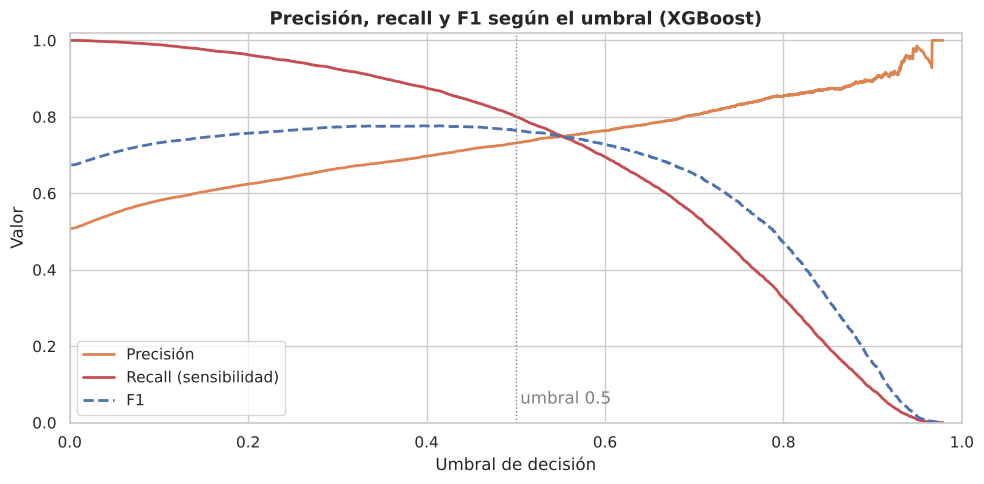

,Umbral,Precisión,Recall,Especificidad,F1,Casos no detectados (FN),Falsas alarmas (FP)
0,0.3,0.6651,0.9249,0.5187,0.7738,527,3269
1,0.4,0.6972,0.8752,0.6072,0.7761,876,2668
2,0.5,0.7315,0.8004,0.6964,0.7644,1401,2062
3,0.6,0.7637,0.6949,0.7778,0.7277,2142,1509
4,0.7,0.8051,0.5456,0.8635,0.6504,3190,927


In [13]:
prec, rec, umbrales = precision_recall_curve(y_test, prob_test[mejor])

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(umbrales, prec[:-1], color='#DD8452', lw=2, label='Precisión')
ax.plot(umbrales, rec[:-1], color='#C44E52', lw=2, label='Recall (sensibilidad)')
f1_curva = 2 * prec[:-1] * rec[:-1] / (prec[:-1] + rec[:-1])
ax.plot(umbrales, f1_curva, color='#4C72B0', lw=2, ls='--', label='F1')
ax.axvline(0.5, color='grey', ls=':', lw=1)
ax.text(0.505, 0.05, 'umbral 0.5', color='grey')
ax.set_xlabel('Umbral de decisión')
ax.set_ylabel('Valor')
ax.set_xlim(0, 1)
ax.set_ylim(0, 1.02)
ax.set_title(f'Precisión, recall y F1 según el umbral ({mejor})', fontsize=13, fontweight='bold')
ax.legend(loc='lower left')
plt.tight_layout()
plt.show()

filas = []
for u in [0.3, 0.4, 0.5, 0.6, 0.7]:
    y_u = (prob_test[mejor] >= u).astype(int)
    vn, fp, fn, vp = confusion_matrix(y_test, y_u).ravel()
    filas.append({'Umbral': u,
                  'Precisión': precision_score(y_test, y_u),
                  'Recall': recall_score(y_test, y_u),
                  'Especificidad': vn / (vn + fp),
                  'F1': f1_score(y_test, y_u),
                  'Casos no detectados (FN)': fn,
                  'Falsas alarmas (FP)': fp})
tabla_umbral = pd.DataFrame(filas)
tabla_umbral.round(4)

El gráfico muestra el equilibrio entre precisión y recall en XGBoost. Con el umbral por defecto de 0.5 el modelo detecta el 80.0% de los casos con una precisión de 73.2%. Si se baja el umbral a 0.4, el recall sube a 87.5% y los casos no detectados bajan de 1 401 a 876, a cambio de 606 falsas alarmas adicionales; el F1 incluso mejora ligeramente (0.776 frente a 0.764). Con 0.3 el recall llega a 92.5%, pero la especificidad cae a 51.9%. En sentido contrario, un umbral de 0.7 eleva la precisión a 80.5% pero deja sin detectar a casi la mitad de los casos (recall de 54.6%).

Para tamizaje, un umbral entre 0.4 y 0.5 ofrece un buen compromiso. La elección final depende del costo de cada tipo de error en el contexto donde se use el modelo.

## 14. Calibración y ajuste a la prevalencia real

Un modelo está **calibrado** si, entre las personas a las que asigna una probabilidad de 70%, aproximadamente el 70% tiene realmente la condición. La curva de calibración agrupa las predicciones en intervalos y compara la probabilidad media predicha con la proporción observada de positivos; un modelo perfectamente calibrado sigue la diagonal.

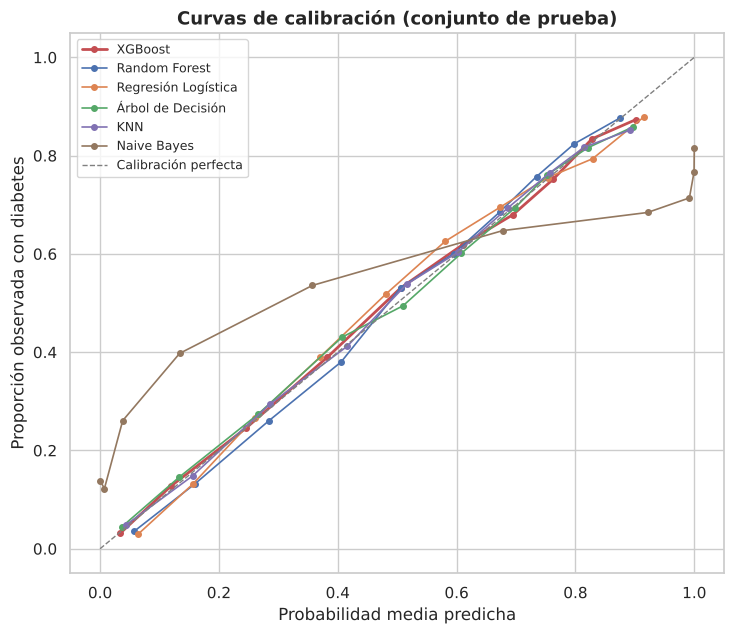

In [14]:
fig, ax = plt.subplots(figsize=(7.5, 6.5))
for nombre in orden:
    frac_pos, prob_media = calibration_curve(y_test, prob_test[nombre], n_bins=10, strategy='quantile')
    ax.plot(prob_media, frac_pos, 'o-', ms=4, color=COLORES_MODELOS[nombre],
            lw=2 if nombre == mejor else 1.2, label=nombre)
ax.plot([0, 1], [0, 1], ls='--', color='grey', lw=1, label='Calibración perfecta')
ax.set_xlabel('Probabilidad media predicha')
ax.set_ylabel('Proporción observada con diabetes')
ax.set_title('Curvas de calibración (conjunto de prueba)', fontsize=13, fontweight='bold')
ax.legend(fontsize=9)
plt.tight_layout()
plt.show()

Los modelos basados en árboles, la Regresión Logística y KNN están bien calibrados: sus curvas siguen de cerca la diagonal en todo el rango, lo que significa que sus probabilidades pueden interpretarse directamente como riesgo (dentro de la muestra 50/50). **Naive Bayes** es la excepción: está mal calibrado y es demasiado extremo. Asigna probabilidades cercanas a 0 a grupos en los que en realidad entre el 12% y el 26% tiene diabetes, y probabilidades cercanas a 1 a grupos en los que la proporción real está entre el 70% y el 80%. Esto es consecuencia directa del supuesto de independencia: al multiplicar la evidencia de variables relacionadas entre sí, el modelo la cuenta varias veces y exagera su confianza.

**Ajuste a la prevalencia de la población**

Como el modelo se entrenó con una muestra 50/50, sus probabilidades están calibradas para una población donde la mitad de las personas tiene diabetes o prediabetes. Para usarlo en la población general, donde la prevalencia es cercana al 13.9%, se aplica la corrección de odds descrita en el marco teórico. El tablero GlucoRisk muestra ambas probabilidades en la página de predicción.

In [15]:
PREVALENCIA = 0.139

def ajustar_prevalencia(p, pi=PREVALENCIA, pi_entrenamiento=0.5):
    odds = p / (1 - p) * (pi / (1 - pi)) / (pi_entrenamiento / (1 - pi_entrenamiento))
    return odds / (1 + odds)

p_modelo = np.array([0.10, 0.25, 0.50, 0.75, 0.90])
tabla_ajuste = pd.DataFrame({
    'Probabilidad del modelo (muestra 50/50)': p_modelo,
    'Probabilidad ajustada (prevalencia 13.9%)': ajustar_prevalencia(p_modelo),
}).round(3)

p_aj = ajustar_prevalencia(prob_test[mejor])
print(f"ROC-AUC con probabilidades originales: {roc_auc_score(y_test, prob_test[mejor]):.4f}")
print(f"ROC-AUC con probabilidades ajustadas:  {roc_auc_score(y_test, p_aj):.4f}")
tabla_ajuste

ROC-AUC con probabilidades originales: 0.8235
ROC-AUC con probabilidades ajustadas:  0.8235


,Probabilidad del modelo (muestra 50/50),Probabilidad ajustada (prevalencia 13.9%)
0,0.10,0.018
1,0.25,0.051
2,0.50,0.139
3,0.75,0.326
4,0.90,0.592


La tabla muestra cuánto cambia la probabilidad al trasladarla a la población general. Una persona a la que el modelo le asigna 50% de probabilidad en la muestra balanceada tendría en realidad un riesgo de 13.9%, que es justamente la prevalencia de la población; una probabilidad de 90% equivale a 59.2%. Como se esperaba, el ROC-AUC es el mismo con ambas probabilidades (0.8235), porque la corrección no altera el orden de las personas: solo cambia la escala en la que se expresa el riesgo.

## 15. Interpretación de los modelos

### Importancia por permutación del mejor modelo

Se mide cuánto cae el ROC-AUC del mejor modelo cuando se desordena cada variable. Para reducir el tiempo de cálculo se usa una muestra de 5 000 registros del conjunto de prueba y 5 repeticiones por variable.

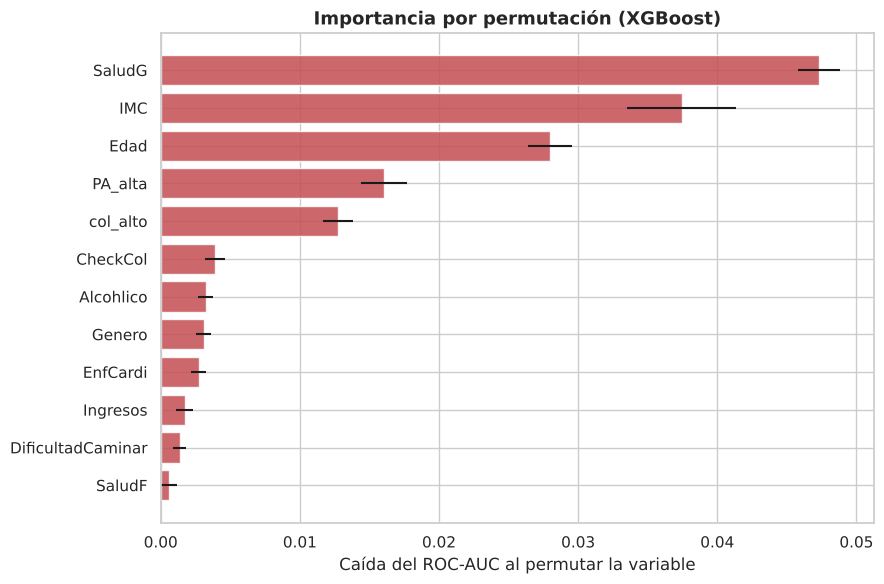

,Variable,Caída del AUC,ds
0,SaludG,0.0473,0.0015
1,IMC,0.0374,0.0039
2,Edad,0.0280,0.0016
3,PA_alta,0.0160,0.0017
4,col_alto,0.0127,0.0011
5,CheckCol,0.0039,0.0007
6,Alcohlico,0.0032,0.0005
7,Genero,0.0031,0.0005
8,EnfCardi,0.0027,0.0005
9,Ingresos,0.0017,0.0006


In [16]:
muestra = X_test.sample(5000, random_state=SEED)
perm = permutation_importance(modelos[mejor], muestra, y_test.loc[muestra.index],
                              scoring='roc_auc', n_repeats=5, random_state=SEED, n_jobs=1)

importancia = (pd.DataFrame({'Variable': variables,
                             'Caída del AUC': perm.importances_mean,
                             'ds': perm.importances_std})
               .sort_values('Caída del AUC', ascending=False)
               .reset_index(drop=True))

top = importancia.head(12).iloc[::-1]
fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(top['Variable'], top['Caída del AUC'], xerr=top['ds'], color='#C44E52', alpha=0.85)
ax.set_xlabel('Caída del ROC-AUC al permutar la variable')
ax.set_title(f'Importancia por permutación ({mejor})', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

importancia.head(10).round(4)

Las tres variables más importantes para XGBoost son la **salud general percibida** (`SaludG`, caída del AUC de 0.047), el **índice de masa corporal** (`IMC`, 0.037) y la **edad** (`Edad`, 0.028). Les siguen la presión arterial alta (`PA_alta`, 0.016) y el colesterol alto (`col_alto`, 0.013). A partir de la sexta variable la importancia cae por debajo de 0.004, lo que indica que el modelo se apoya sobre todo en estas cinco. Este resultado coincide con el análisis bivariado, donde estas mismas variables mostraron las asociaciones más fuertes con la diabetes.

### Odds ratios de la Regresión Logística

Como la Regresión Logística se entrenó con variables estandarizadas, cada odds ratio representa cuánto se multiplican los odds de tener diabetes cuando la variable aumenta una desviación estándar, manteniendo las demás constantes. Valores mayores que 1 indican mayor riesgo y valores menores que 1, menor riesgo.

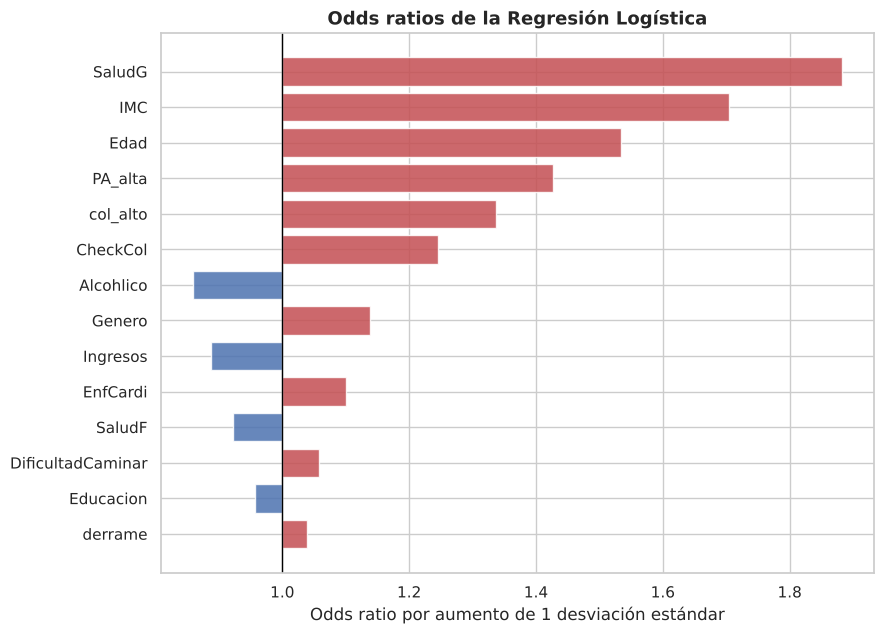

,Variable,Coeficiente,Odds ratio
0,SaludG,0.632,1.882
1,IMC,0.533,1.705
2,Edad,0.428,1.534
3,PA_alta,0.356,1.427
4,col_alto,0.291,1.337
5,CheckCol,0.220,1.245
6,Alcohlico,-0.151,0.859
7,Genero,0.129,1.138
8,Ingresos,-0.119,0.888
9,EnfCardi,0.095,1.100


In [17]:
reg_log = modelos['Regresión Logística']
coef = reg_log.named_steps['clf'].coef_[0]

odds = (pd.DataFrame({'Variable': variables, 'Coeficiente': coef, 'Odds ratio': np.exp(coef)})
        .assign(abs_coef=lambda t: t['Coeficiente'].abs())
        .sort_values('abs_coef', ascending=False)
        .drop(columns='abs_coef')
        .reset_index(drop=True))

graf = odds.head(14).iloc[::-1]
colores = ['#C44E52' if o > 1 else '#4C72B0' for o in graf['Odds ratio']]
fig, ax = plt.subplots(figsize=(9, 6.5))
ax.barh(graf['Variable'], graf['Odds ratio'] - 1, left=1, color=colores, alpha=0.85)
ax.axvline(1, color='black', lw=1)
ax.set_xlabel('Odds ratio por aumento de 1 desviación estándar')
ax.set_title('Odds ratios de la Regresión Logística', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

odds.head(12).round(3)

La Regresión Logística confirma el mismo grupo de variables. Un aumento de una desviación estándar en la salud general percibida (que en esta escala significa *peor* salud) multiplica los odds de tener diabetes por 1.88; en el IMC, por 1.71; y en la edad, por 1.53. Tener presión arterial alta (1.43) y colesterol alto (1.34) también aumenta el riesgo. En sentido contrario, el consumo alto de alcohol (0.86) y los mayores ingresos (0.89) se asocian con menores odds.

El efecto protector del alcohol no debe interpretarse como causal: probablemente refleja que las personas con diabetes diagnosticada reducen su consumo por indicación médica, o que el consumo alto se concentra en grupos con otras características. El signo negativo de `SaludF` aparece porque la salud física está muy relacionada con `SaludG` y con `DificultadCaminar`, que ya recogen ese efecto en el modelo.

### Primeras reglas del Árbol de Decisión

Para ilustrar cómo razona un árbol, se muestran los tres primeros niveles del Árbol de Decisión entrenado. Cada nodo indica la regla de división, el índice de Gini, el número de observaciones y la clase mayoritaria.

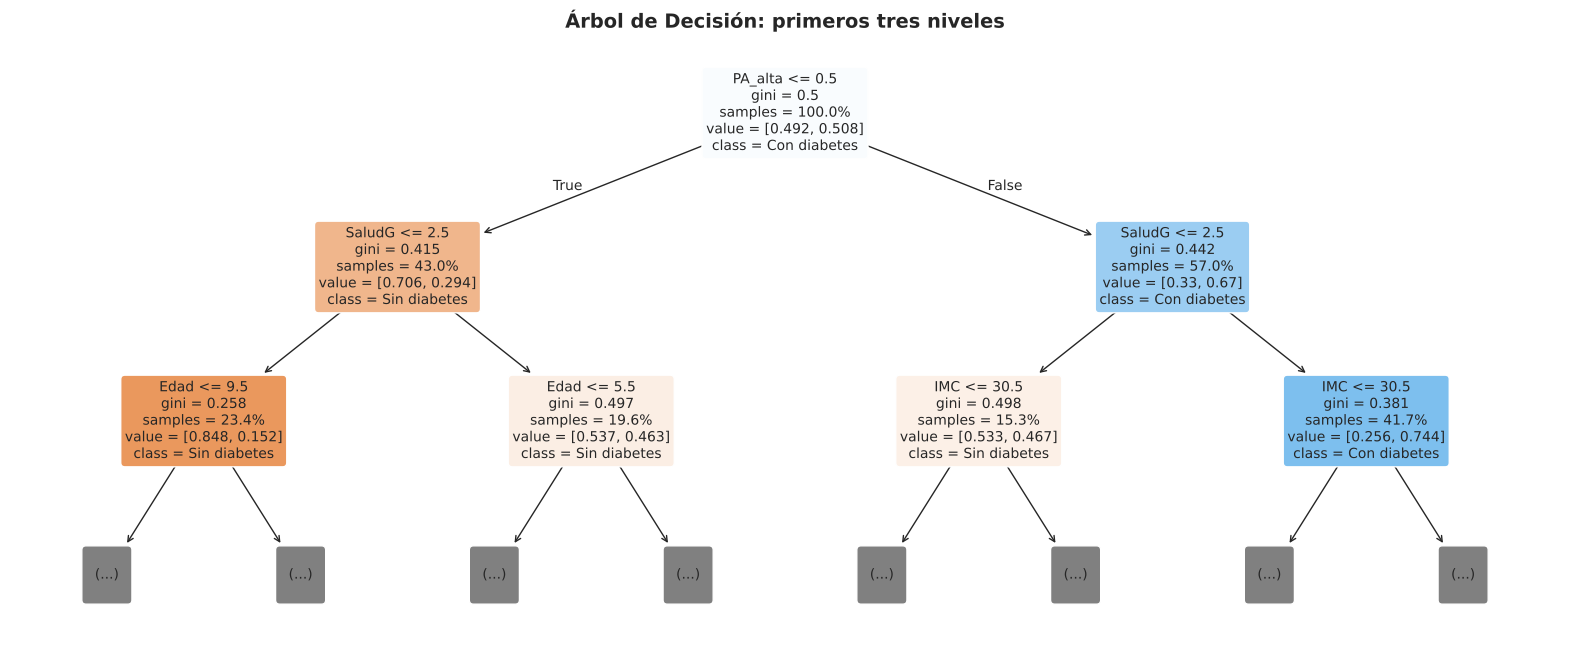

In [18]:
fig, ax = plt.subplots(figsize=(20, 8))
plot_tree(modelos['Árbol de Decisión'], max_depth=2, feature_names=variables,
          class_names=['Sin diabetes', 'Con diabetes'], filled=True, rounded=True,
          impurity=True, proportion=True, fontsize=10, ax=ax)
ax.set_title('Árbol de Decisión: primeros tres niveles', fontsize=14, fontweight='bold')
plt.show()

La primera división del árbol se hace por **presión arterial alta**. Entre las personas sin hipertensión (43% de la muestra de entrenamiento), solo el 29.4% tiene diabetes; entre las hipertensas (57%), la proporción sube a 67.0%. En ambos lados, la segunda división es la **salud general percibida**: quienes la califican como excelente o muy buena (`SaludG` ≤ 2) tienen un riesgo mucho menor. El grupo de mayor riesgo en el tercer nivel es el de personas hipertensas con salud general regular o mala, que representan el 41.7% de la muestra y en el que el 74.4% tiene diabetes. Las divisiones siguientes usan la edad y el IMC. Las reglas del árbol son coherentes con los factores de riesgo descritos en la literatura.

## 16. Selección del modelo final

In [19]:
resumen_final = tabla_resultados[['Modelo', 'ROC-AUC', 'Recall', 'F1', 'AUC CV (media)', 'AUC CV (ds)',
                                  'AUC entrenamiento', 'Tiempo de ajuste (s)']].copy()
resumen_final['Brecha entrenamiento − prueba'] = resumen_final['AUC entrenamiento'] - resumen_final['ROC-AUC']
resumen_final.drop(columns='AUC entrenamiento').round(4)

,Modelo,ROC-AUC,Recall,F1,AUC CV (media),AUC CV (ds),Tiempo de ajuste (s),Brecha entrenamiento − prueba
0,XGBoost,0.8235,0.8004,0.7644,0.8256,0.0044,1.5557,0.0239
1,Random Forest,0.8209,0.7956,0.7598,0.8235,0.0037,3.7123,0.0428
2,Regresión Logística,0.8174,0.7726,0.7549,0.8200,0.0036,0.1123,0.0029
3,Árbol de Decisión,0.8105,0.7912,0.7508,0.8104,0.0047,0.1126,0.0133
4,KNN,0.8053,0.7900,0.7526,0.8053,0.0050,0.0225,0.0232
5,Naive Bayes,0.7800,0.7181,0.7217,0.7814,0.0043,0.0211,0.0015


Se selecciona **XGBoost** como modelo final porque:

- Tiene el mayor ROC-AUC en el conjunto de prueba (0.8235) y en validación cruzada (0.8256 ± 0.0044).
- Obtiene el mayor recall (80.0%) y el mayor F1 (0.764), lo que lo hace adecuado para tamizaje.
- Su sobreajuste es moderado (+0.024), bastante menor que el de Random Forest.
- Sus probabilidades están bien calibradas, por lo que pueden ajustarse a la prevalencia real.
- Su tiempo de entrenamiento es bajo (alrededor de 1.5 segundos).

La **Regresión Logística** queda como una alternativa muy razonable cuando se prioriza la interpretabilidad: pierde solo 0.006 de AUC, prácticamente no se sobreajusta y sus coeficientes se explican directamente como odds ratios. Por eso el tablero GlucoRisk usa XGBoost para la predicción y la Regresión Logística para explicar el aporte de cada variable en el perfil simulado.

## 17. Conclusiones

- Con las 21 variables de la encuesta BRFSS 2015, y sin ningún examen de laboratorio, es posible distinguir a las personas con diabetes o prediabetes con un ROC-AUC de 0.82. Es un desempeño adecuado para una herramienta de tamizaje, aunque no para un diagnóstico.
- Los seis modelos obtienen resultados cercanos: entre el mejor (XGBoost, 0.824) y el quinto (KNN, 0.805) hay menos de dos puntos de AUC. El límite lo pone la información disponible en la encuesta, que es autorreportada y no incluye variables clínicas como la glucosa o la hemoglobina glicosilada.
- Los resultados son estables y generalizan bien: la validación cruzada coincide con el conjunto de prueba y ningún modelo presenta un sobreajuste grave.
- Las variables más influyentes son la salud general percibida, el IMC, la edad, la presión arterial alta y el colesterol alto, lo que coincide con el análisis bivariado y con los factores de riesgo reconocidos por la literatura médica.
- El umbral de decisión puede ajustarse según el uso: bajarlo a 0.4 aumenta la detección de casos del 80% al 87.5%, a costa de más falsas alarmas.
- Como el modelo se entrenó con una muestra balanceada, sus probabilidades deben ajustarse a la prevalencia real (≈ 13.9%) antes de interpretarlas como riesgo individual en la población general. Este ajuste no modifica la capacidad de discriminación del modelo.
- **Limitaciones**: los datos son autorreportados y de corte transversal, por lo que el modelo identifica asociaciones y no relaciones causales. Además, la encuesta corresponde a adultos de EE. UU. en 2015, de modo que su aplicación en otras poblaciones requeriría validarlo con datos locales.

**Referencias**

- Breiman, L. (2001). Random forests. *Machine Learning, 45*(1), 5–32.
- Centers for Disease Control and Prevention. (2016). *Behavioral Risk Factor Surveillance System: 2015 survey data and documentation*. U.S. Department of Health and Human Services.
- Chen, T., & Guestrin, C. (2016). XGBoost: A scalable tree boosting system. *Proceedings of the 22nd ACM SIGKDD International Conference on Knowledge Discovery and Data Mining*, 785–794.
- Fawcett, T. (2006). An introduction to ROC analysis. *Pattern Recognition Letters, 27*(8), 861–874.
- Hastie, T., Tibshirani, R., & Friedman, J. (2009). *The elements of statistical learning* (2.ª ed.). Springer.
- Pedregosa, F., et al. (2011). Scikit-learn: Machine learning in Python. *Journal of Machine Learning Research, 12*, 2825–2830.
- Saerens, M., Latinne, P., & Decaestecker, C. (2002). Adjusting the outputs of a classifier to new a priori probabilities: A simple procedure. *Neural Computation, 14*(1), 21–41.
- Teboul, A. (2021). *Diabetes Health Indicators Dataset* [Conjunto de datos]. Kaggle. https://www.kaggle.com/datasets/alexteboul/diabetes-health-indicators-dataset
- Xie, Z., Nikolayeva, O., Luo, J., & Li, D. (2019). Building risk prediction models for type 2 diabetes using machine learning techniques. *Preventing Chronic Disease, 16*, E130.